In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import joblib
import os

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
data = load_breast_cancer()

df = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

df["target"] = data.target

df["diagnosis"] = df["target"].map({
    0: "Malignant",
    1: "Benign"
})

print("Dataset loaded successfully!")
df.head()

Dataset loaded successfully!


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,Malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,Malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,Malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,Malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,Malignant


In [3]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum().sum())

Dataset Shape: (569, 32)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000



Missing Values:
0


In [4]:
display(df.head())

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,Malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,Malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,Malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,Malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,Malignant


In [5]:
X = df[data.feature_names]

y = df["target"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

Features Shape: (569, 30)
Target Shape: (569,)

Target Distribution:
target
1    357
0    212
Name: count, dtype: int64


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (455, 30)
Testing Data: (114, 30)


In [8]:
model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [9]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

results["Actual_Diagnosis"] = results["Actual"].map({
    0: "Malignant",
    1: "Benign"
})

results["Predicted_Diagnosis"] = results["Predicted"].map({
    0: "Malignant",
    1: "Benign"
})

results["Prediction_Status"] = np.where(
    results["Actual"] == results["Predicted"],
    "Correct",
    "Incorrect"
)

display(results.head(15))

,Actual,Predicted,Actual_Diagnosis,Predicted_Diagnosis,Prediction_Status
0,0,0,Malignant,Malignant,Correct
1,1,1,Benign,Benign,Correct
2,0,0,Malignant,Malignant,Correct
3,1,1,Benign,Benign,Correct
4,0,0,Malignant,Malignant,Correct
5,1,1,Benign,Benign,Correct
6,1,1,Benign,Benign,Correct
7,0,0,Malignant,Malignant,Correct
8,0,0,Malignant,Malignant,Correct
9,0,0,Malignant,Malignant,Correct


In [10]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[1, 0]
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[68  4]
 [ 3 39]]


In [11]:
TN, FP, FN, TP = cm.ravel()

print("True Negative (TN):", TN)
print("False Positive (FP):", FP)
print("False Negative (FN):", FN)
print("True Positive (TP):", TP)

True Negative (TN): 68
False Positive (FP): 4
False Negative (FN): 3
True Positive (TP): 39


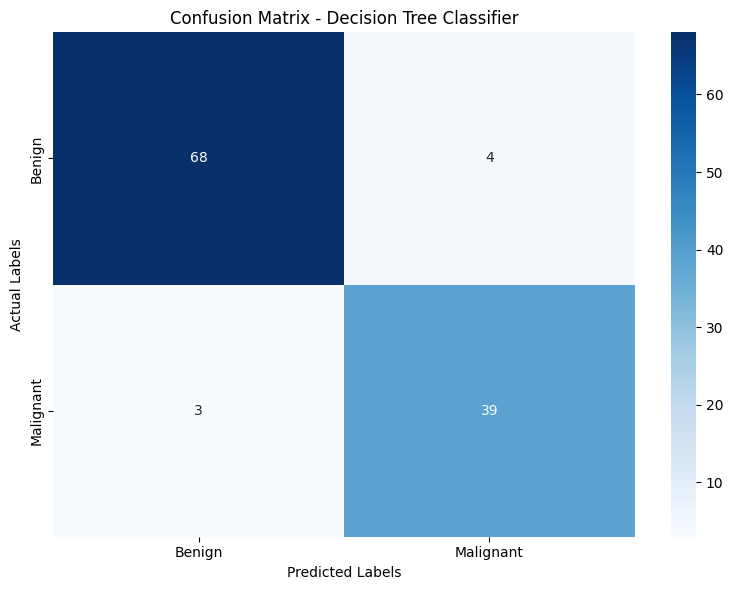

In [12]:
os.makedirs("charts", exist_ok=True)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"]
)

plt.title("Confusion Matrix - Decision Tree Classifier")
plt.xlabel("Predicted Labels")
plt.ylabel("Actual Labels")

plt.tight_layout()

plt.savefig(
    "charts/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

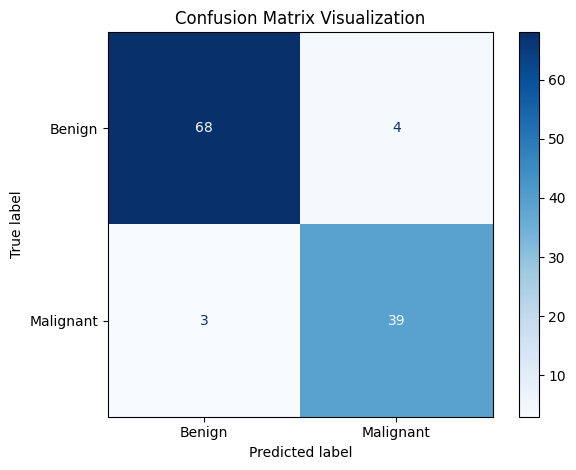

In [13]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix Visualization")

plt.tight_layout()
plt.show()

In [14]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    pos_label=0
)

recall = recall_score(
    y_test,
    y_pred,
    pos_label=0
)

f1 = f1_score(
    y_test,
    y_pred,
    pos_label=0
)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Accuracy: 0.9385964912280702
Accuracy Percentage: 93.85964912280701 %
Precision: 0.9069767441860465
Recall: 0.9285714285714286
F1 Score: 0.9176470588235294


In [15]:
report = classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Malignant", "Benign"],
    output_dict=True
)

report_df = pd.DataFrame(report).transpose()

display(report_df)

,precision,recall,f1-score,support
Malignant,0.906977,0.928571,0.917647,42.000000
Benign,0.957746,0.944444,0.951049,72.000000
accuracy,0.938596,0.938596,0.938596,0.938596
macro avg,0.932362,0.936508,0.934348,114.000000
weighted avg,0.939042,0.938596,0.938743,114.000000


In [16]:
print("CONFUSION MATRIX INTERPRETATION")

print("Total Predictions:", len(y_test))
print("True Negatives:", TN)
print("False Positives:", FP)
print("False Negatives:", FN)
print("True Positives:", TP)

print("\nCorrect Predictions:", TN + TP)
print("Incorrect Predictions:", FP + FN)

print("\nAccuracy Percentage:", round(accuracy * 100, 2), "%")

CONFUSION MATRIX INTERPRETATION
Total Predictions: 114
True Negatives: 68
False Positives: 4
False Negatives: 3
True Positives: 39

Correct Predictions: 107
Incorrect Predictions: 7

Accuracy Percentage: 93.86 %


In [17]:
confusion_df = pd.DataFrame(
    cm,
    index=["Actual_Benign", "Actual_Malignant"],
    columns=["Predicted_Benign", "Predicted_Malignant"]
)

confusion_df.to_csv("confusion_matrix.csv")

display(confusion_df)

,Predicted_Benign,Predicted_Malignant
Actual_Benign,68,4
Actual_Malignant,3,39


In [18]:
confusion_results = pd.DataFrame({
    "Metric": [
        "True Negative",
        "False Positive",
        "False Negative",
        "True Positive"
    ],
    "Value": [TN, FP, FN, TP]
})

confusion_results.to_csv(
    "confusion_matrix_results.csv",
    index=False
)

display(confusion_results)

,Metric,Value
0,True Negative,68
1,False Positive,4
2,False Negative,3
3,True Positive,39


In [19]:
results.to_csv(
    "classification_predictions.csv",
    index=False
)

print("Prediction results saved!")

Prediction results saved!


In [20]:
evaluation_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Accuracy Percentage",
        "Precision",
        "Recall",
        "F1 Score",
        "True Negative",
        "False Positive",
        "False Negative",
        "True Positive"
    ],
    "Value": [
        accuracy,
        accuracy * 100,
        precision,
        recall,
        f1,
        TN,
        FP,
        FN,
        TP
    ]
})

evaluation_summary.to_csv(
    "evaluation_summary.csv",
    index=False
)

display(evaluation_summary)

,Metric,Value
0,Accuracy,0.938596
1,Accuracy Percentage,93.859649
2,Precision,0.906977
3,Recall,0.928571
4,F1 Score,0.917647
5,True Negative,68.000000
6,False Positive,4.000000
7,False Negative,3.000000
8,True Positive,39.000000


In [21]:
report_df.to_csv("classification_report.csv")

print("Classification report saved!")

Classification report saved!


In [22]:
df.to_csv("breast_cancer_dataset.csv", index=False)

X.to_csv("classification_features.csv", index=False)

y.to_csv("classification_target.csv", index=False)

df.to_csv("prepared_classification_dataset.csv", index=False)

print("Dataset CSV files saved successfully!")

Dataset CSV files saved successfully!


In [23]:
joblib.dump(
    model,
    "decision_tree_model.joblib"
)

print("Model saved successfully!")

Model saved successfully!


In [24]:
import os

for root, dirs, files_list in os.walk("."):
    dirs[:] = [
        d for d in dirs
        if d not in [".config", ".ipynb_checkpoints"]
    ]

    for file in files_list:
        if file != "":
            print(os.path.join(root, file))

./breast_cancer_dataset.csv
./decision_tree_model.joblib
./confusion_matrix_results.csv
./classification_report.csv
./classification_features.csv
./confusion_matrix.csv
./prepared_classification_dataset.csv
./evaluation_summary.csv
./classification_predictions.csv
./classification_target.csv
./charts/confusion_matrix.png
./sample_data/README.md
./sample_data/anscombe.json
./sample_data/california_housing_test.csv
./sample_data/mnist_test.csv
./sample_data/mnist_train_small.csv
./sample_data/california_housing_train.csv


In [25]:
from google.colab import files
files.download("breast_cancer_dataset.csv")
files.download("prepared_classification_dataset.csv")
files.download("classification_features.csv")
files.download("classification_target.csv")
files.download("confusion_matrix.csv")
files.download("confusion_matrix_results.csv")
files.download("classification_predictions.csv")
files.download("evaluation_summary.csv")
files.download("classification_report.csv")
files.download("decision_tree_model.joblib")
files.download("charts/confusion_matrix.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (12 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>